# **PLOTTING CHARTS FOR NBA TEAMS EFFICIENCY EVALUATION**

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv ('NBA efficiency week 6.csv')

In [ ]:
data

,Rk,Team,ORtg,DRtg,NRtg
0,1.0,San Antonio Spurs,118.8,106.7,12.1
1,2.0,Minnesota Timberwolves,114.1,104.5,9.6
2,3.0,Boston Celtics,116.7,107.2,9.5
3,4.0,Memphis Grizzlies,121.3,112.2,9.1
4,5.0,Houston Rockets,122.0,114.1,7.9
5,6.0,Los Angeles Lakers,120.4,114.2,6.2
6,7.0,Portland Trail Blazers,117.1,111.2,5.9
7,8.0,New York Knicks,114.3,108.4,5.9
8,9.0,Detroit Pistons,115.4,110.5,4.9
9,10.0,Oklahoma City Thunder,114.2,110.5,3.7


In [ ]:
data.describe()

,Rk,ORtg,DRtg,NRtg
count,30.000000,30.000000,30.000000,30.00000
mean,15.500000,114.326667,114.376667,-0.05000
std,8.803408,4.109529,4.272420,6.99437
min,1.000000,104.400000,104.500000,-12.40000
25%,8.250000,111.600000,111.450000,-6.15000
50%,15.500000,114.150000,114.700000,0.70000
75%,22.750000,117.000000,116.775000,5.65000
max,30.000000,122.000000,122.200000,12.10000


In [ ]:
data = data.drop(columns=['Rk'])
data

,Team,ORtg,DRtg,NRtg
0,San Antonio Spurs,118.8,106.7,12.1
1,Minnesota Timberwolves,114.1,104.5,9.6
2,Boston Celtics,116.7,107.2,9.5
3,Memphis Grizzlies,121.3,112.2,9.1
4,Houston Rockets,122.0,114.1,7.9
5,Los Angeles Lakers,120.4,114.2,6.2
6,Portland Trail Blazers,117.1,111.2,5.9
7,New York Knicks,114.3,108.4,5.9
8,Detroit Pistons,115.4,110.5,4.9
9,Oklahoma City Thunder,114.2,110.5,3.7


In [ ]:
data = data.dropna()
data

,Team,ORtg,DRtg,NRtg
0,San Antonio Spurs,118.8,106.7,12.1
1,Minnesota Timberwolves,114.1,104.5,9.6
2,Boston Celtics,116.7,107.2,9.5
3,Memphis Grizzlies,121.3,112.2,9.1
4,Houston Rockets,122.0,114.1,7.9
5,Los Angeles Lakers,120.4,114.2,6.2
6,Portland Trail Blazers,117.1,111.2,5.9
7,New York Knicks,114.3,108.4,5.9
8,Detroit Pistons,115.4,110.5,4.9
9,Oklahoma City Thunder,114.2,110.5,3.7


In [ ]:
data.isna().sum()

,0
Team,0
ORtg,0
DRtg,0
NRtg,0


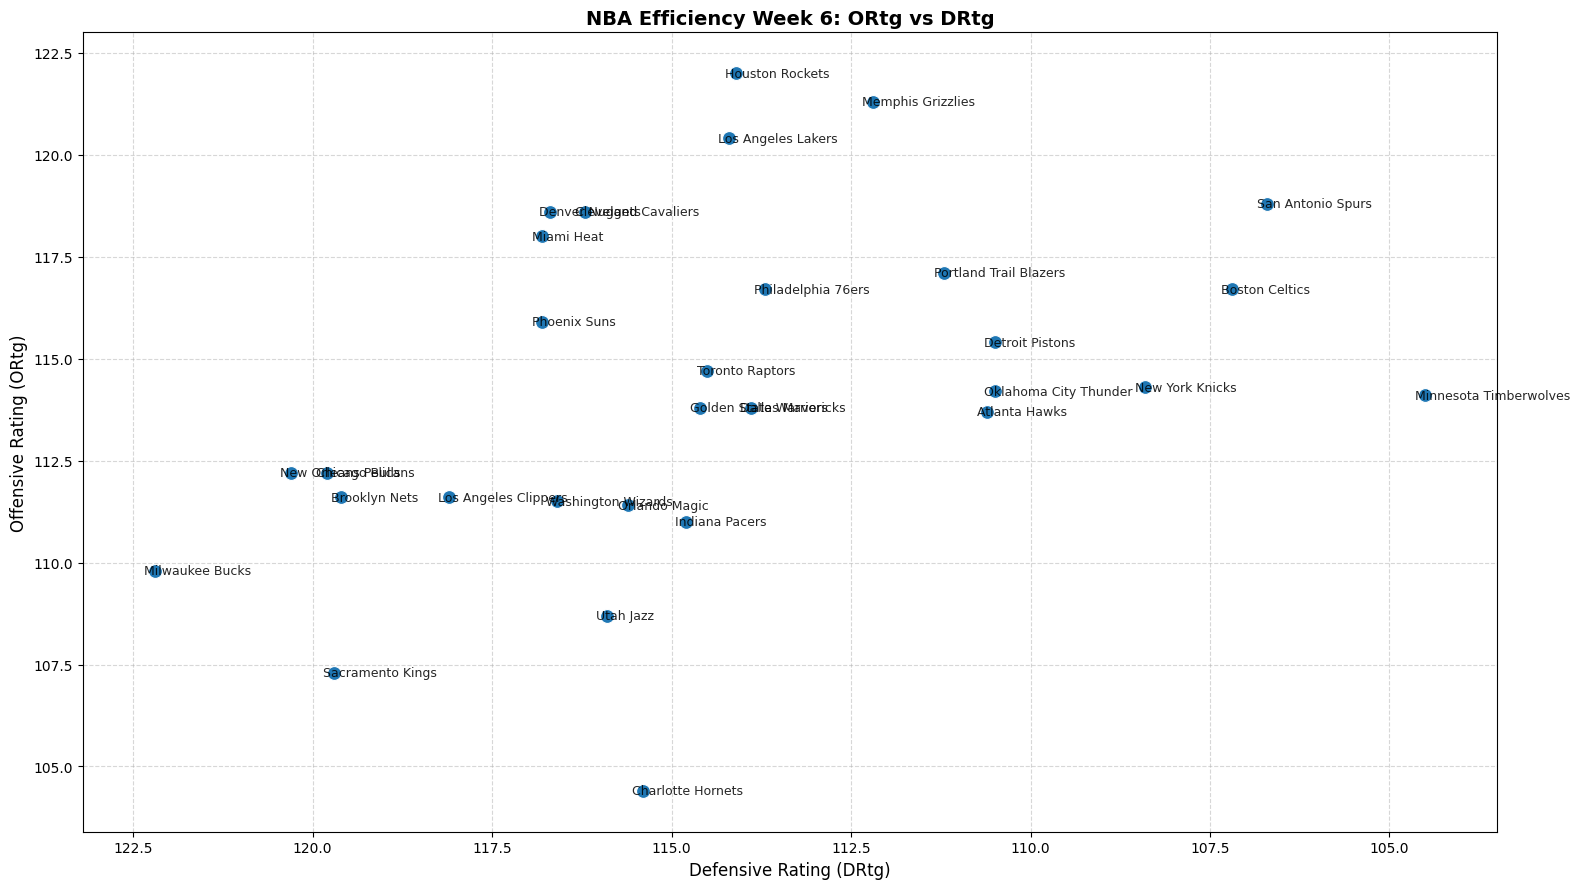

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 9))
sns.scatterplot(data=data, x='DRtg', y='ORtg', s=100)

# Annotate team names using the correct coordinate mapping
for i, row in data.iterrows():
    plt.text(row['DRtg'] + 0.15, row['ORtg'], row['Team'], fontsize=9, alpha=0.85, va='center')

plt.title('NBA Efficiency Week 6: ORtg vs DRtg', fontsize=14, fontweight='bold')
plt.xlabel('Defensive Rating (DRtg)', fontsize=12)
plt.ylabel('Offensive Rating (ORtg)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Calculate optimum limits dynamically based on the dataset with safety padding
drtg_min, drtg_max = data['DRtg'].min(), data['DRtg'].max()
ortg_min, ortg_max = data['ORtg'].min(), data['ORtg'].max()

# Lower DRtg (better defense) and higher ORtg (better offense) are top-right quadrant goals
# X-axis: inverted (low DRtg on the right, high DRtg on the left)
plt.xlim(drtg_max + 1, drtg_min - 1)

# Y-axis: standard (high ORtg on top, low ORtg on the bottom)
plt.ylim(ortg_min - 1, ortg_max + 1)

plt.tight_layout()
plt.show()

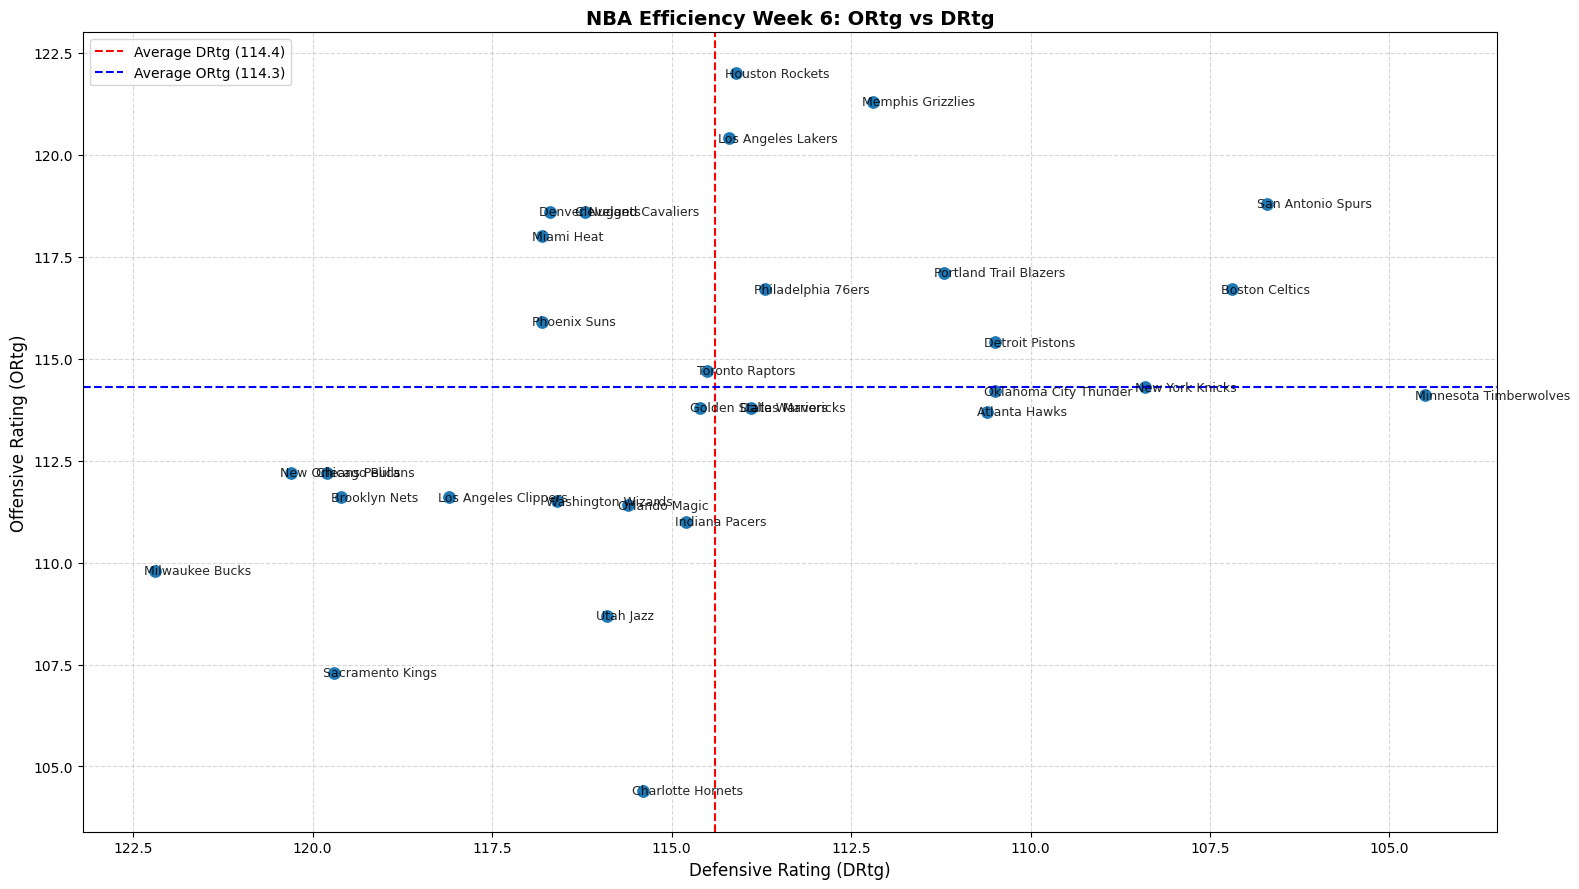

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 9))
sns.scatterplot(data=data, x='DRtg', y='ORtg', s=100)

# Annotate team names using the correct coordinate mapping
for i, row in data.iterrows():
    plt.text(row['DRtg'] + 0.15, row['ORtg'], row['Team'], fontsize=9, alpha=0.85, va='center')

plt.title('NBA Efficiency Week 6: ORtg vs DRtg', fontsize=14, fontweight='bold')
plt.xlabel('Defensive Rating (DRtg)', fontsize=12)
plt.ylabel('Offensive Rating (ORtg)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Draw reference lines at user specified averages
plt.axvline(x=114.4, color='red', linestyle='--', linewidth=1.5, label='Average DRtg (114.4)')
plt.axhline(y=114.3, color='blue', linestyle='--', linewidth=1.5, label='Average ORtg (114.3)')

# Calculate optimum limits dynamically based on the dataset with safety padding
drtg_min, drtg_max = data['DRtg'].min(), data['DRtg'].max()
ortg_min, ortg_max = data['ORtg'].min(), data['ORtg'].max()

# Lower DRtg (better defense) and higher ORtg (better offense) are top-right quadrant goals
# X-axis: inverted (low DRtg on the right, high DRtg on the left)
plt.xlim(drtg_max + 1, drtg_min - 1)

# Y-axis: standard (high ORtg on top, low ORtg on the bottom)
plt.ylim(ortg_min - 1, ortg_max + 1)

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import csv
import json
import os
import re
import time
from urllib.parse import urlparse
import requests

# Paste each team's direct image URL from your browser ("Copy image address")
TEAM_LOGO_URLS = {
    "San Antonio Spurs": "https://content.sportslogos.net/logos/6/233/thumbs/828.gif",
    "Minnesota Timberwolves": "https://content.sportslogos.net/logos/6/232/thumbs/minnesota-timberwolves-logo-primary-2027-23230982027-thumb.png",
    "Boston Celtics": "https://content.sportslogos.net/logos/6/213/thumbs/slhg02hbef3j1ov4lsnwyol5o.gif",
    "Memphis Grizzlies": "https://content.sportslogos.net/logos/6/231/thumbs/23172772019.gif",
    "Houston Rockets": "https://content.sportslogos.net/logos/6/230/thumbs/houston-rockets-alternate-logo-2027-23033212027-thumb.png",
    "Los Angeles Lakers": "https://content.sportslogos.net/logos/6/237/thumbs/23773242024.gif",
    "Portland Trail Blazers": "https://content.sportslogos.net/logos/6/239/thumbs/23997252018.gif",
    "New York Knicks": "https://content.sportslogos.net/logos/6/216/thumbs/21671702024.gif",
    "Detroit Pistons": "https://content.sportslogos.net/logos/6/223/thumbs/22321642018.gif",
    "Oklahoma City Thunder": "https://content.sportslogos.net/logos/6/2687/thumbs/oklahoma-city-thunder-logo-primary-2009-9699-thumb.png",
    "Atlanta Hawks": "https://content.sportslogos.net/logos/6/220/thumbs/22081902021.gif",
    "Philadelphia 76ers": "https://content.sportslogos.net/logos/6/218/thumbs/21870342016.gif",
    "Cleveland Cavaliers": "https://content.sportslogos.net/logos/6/222/thumbs/22254472023.gif",
    "Denver Nuggets": "https://content.sportslogos.net/logos/6/229/thumbs/22989262019.gif",
    "Miami Heat": "https://content.sportslogos.net/logos/6/214/thumbs/burm5gh2wvjti3xhei5h16k8e.gif",
    "Toronto Raptors": "https://content.sportslogos.net/logos/6/227/thumbs/22770242021.gif",
    "Dallas Mavericks": "https://content.sportslogos.net/logos/6/228/thumbs/22851182018.gif",
    "Golden State Warriors": "https://content.sportslogos.net/logos/6/235/thumbs/23531522020.gif",
    "Phoenix Suns": "https://content.sportslogos.net/logos/6/238/thumbs/23843702014.gif",
    "Indiana Pacers": "https://content.sportslogos.net/logos/6/224/thumbs/indiana-pacers-alternate-logo-2026-22443882026-thumb.png",
    "Orlando Magic": "https://content.sportslogos.net/logos/6/217/thumbs/orlando-magic-logo-primary-2026-21794952026-thumb.png",
    "Washington Wizards": "https://content.sportslogos.net/logos/6/219/thumbs/washington-wizards-logo-primary-2016-8780-thumb.png",
    "Los Angeles Clippers": "https://content.sportslogos.net/logos/6/236/thumbs/23655422025.gif",
    "Utah Jazz": "https://content.sportslogos.net/logos/6/234/thumbs/utah-jazz-alternate-logo-2026-23423312026-thumb.png",
    "Chicago Bulls": "https://content.sportslogos.net/logos/6/221/thumbs/hj3gmh82w9hffmeh3fjm5h874.gif",
    "Brooklyn Nets": "https://content.sportslogos.net/logos/6/3786/thumbs/brooklyn-nets-logo-primary-2025-9021-thumb.png",
    "New Orleans Pelicans": "https://content.sportslogos.net/logos/6/4962/thumbs/496222272014.gif",
    "Charlotte Hornets": "https://content.sportslogos.net/logos/6/5120/thumbs/512019262015.gif",
    "Milwaukee Bucks": "https://content.sportslogos.net/logos/6/225/thumbs/22538642016.gif",
    "Sacramento Kings": "https://content.sportslogos.net/logos/6/240/thumbs/24040432017.gif",
}

OUTPUT_DIR = "nba_logos"
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/131.0.0.0 Safari/537.36"
    ),
    "Referer": "https://www.sportslogos.net/",
}


def safe_filename(team_name: str, ext: str) -> str:
    clean = re.sub(r'[\\/:*?"<>|]+', "", team_name).strip()
    return f"{clean}{ext}"


def get_extension(url: str, content_type: str) -> str:
    path_ext = os.path.splitext(urlparse(url).path)[1].lower()
    if path_ext in {".png", ".gif", ".jpg", ".jpeg", ".webp", ".svg"}:
        return path_ext

    ct_map = {
        "image/png": ".png",
        "image/gif": ".gif",
        "image/jpeg": ".jpg",
        "image/webp": ".webp",
        "image/svg+xml": ".svg",
    }
    for mime, ext in ct_map.items():
        if mime in content_type:
            return ext
    return ".png"


def download_image(session: requests.Session, url: str, team_name: str) -> tuple[str | None, str]:
    try:
        resp = session.get(url, headers=HEADERS, timeout=20)
        resp.raise_for_status()

        content_type = resp.headers.get("Content-Type", "").lower()
        ext = get_extension(url, content_type)
        out_path = os.path.join(OUTPUT_DIR, safe_filename(team_name, ext))

        with open(out_path, "wb") as f:
            f.write(resp.content)

        if os.path.getsize(out_path) == 0:
            return None, "empty_file"

        return out_path, "saved"
    except requests.RequestException as exc:
        return None, f"failed ({type(exc).__name__})"


def main() -> None:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    session = requests.Session()
    results = []

    for team, url in TEAM_LOGO_URLS.items():
        clean_url = url.strip()
        if not clean_url:
            results.append({
                "team": team,
                "logo_url": "",
                "saved_path": None,
                "status": "missing_url",
            })
            print(f"{team:26} | missing_url")
            continue

        saved_path, status = download_image(session, clean_url, team)
        results.append({
            "team": team,
            "logo_url": clean_url,
            "saved_path": saved_path,
            "status": status,
        })
        print(f"{team:26} | {status:15} | {clean_url}")
        time.sleep(0.2)

    with open("team_logo_urls.json", "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)

    with open("team_logo_urls.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f, fieldnames=["team", "logo_url", "saved_path", "status"]
        )
        writer.writeheader()
        writer.writerows(results)

    saved_count = sum(1 for r in results if r["status"] == "saved")
    print(f"\nDone: {saved_count}/{len(TEAM_LOGO_URLS)} logos saved to '{OUTPUT_DIR}/'.")


if __name__ == "__main__":
    main()

San Antonio Spurs          | saved           | https://content.sportslogos.net/logos/6/233/thumbs/828.gif
Minnesota Timberwolves     | saved           | https://content.sportslogos.net/logos/6/232/thumbs/minnesota-timberwolves-logo-primary-2027-23230982027-thumb.png
Boston Celtics             | saved           | https://content.sportslogos.net/logos/6/213/thumbs/slhg02hbef3j1ov4lsnwyol5o.gif
Memphis Grizzlies          | saved           | https://content.sportslogos.net/logos/6/231/thumbs/23172772019.gif
Houston Rockets            | saved           | https://content.sportslogos.net/logos/6/230/thumbs/houston-rockets-alternate-logo-2027-23033212027-thumb.png
Los Angeles Lakers         | saved           | https://content.sportslogos.net/logos/6/237/thumbs/23773242024.gif
Portland Trail Blazers     | saved           | https://content.sportslogos.net/logos/6/239/thumbs/23997252018.gif
New York Knicks            | saved           | https://content.sportslogos.net/logos/6/216/thumbs/216717020

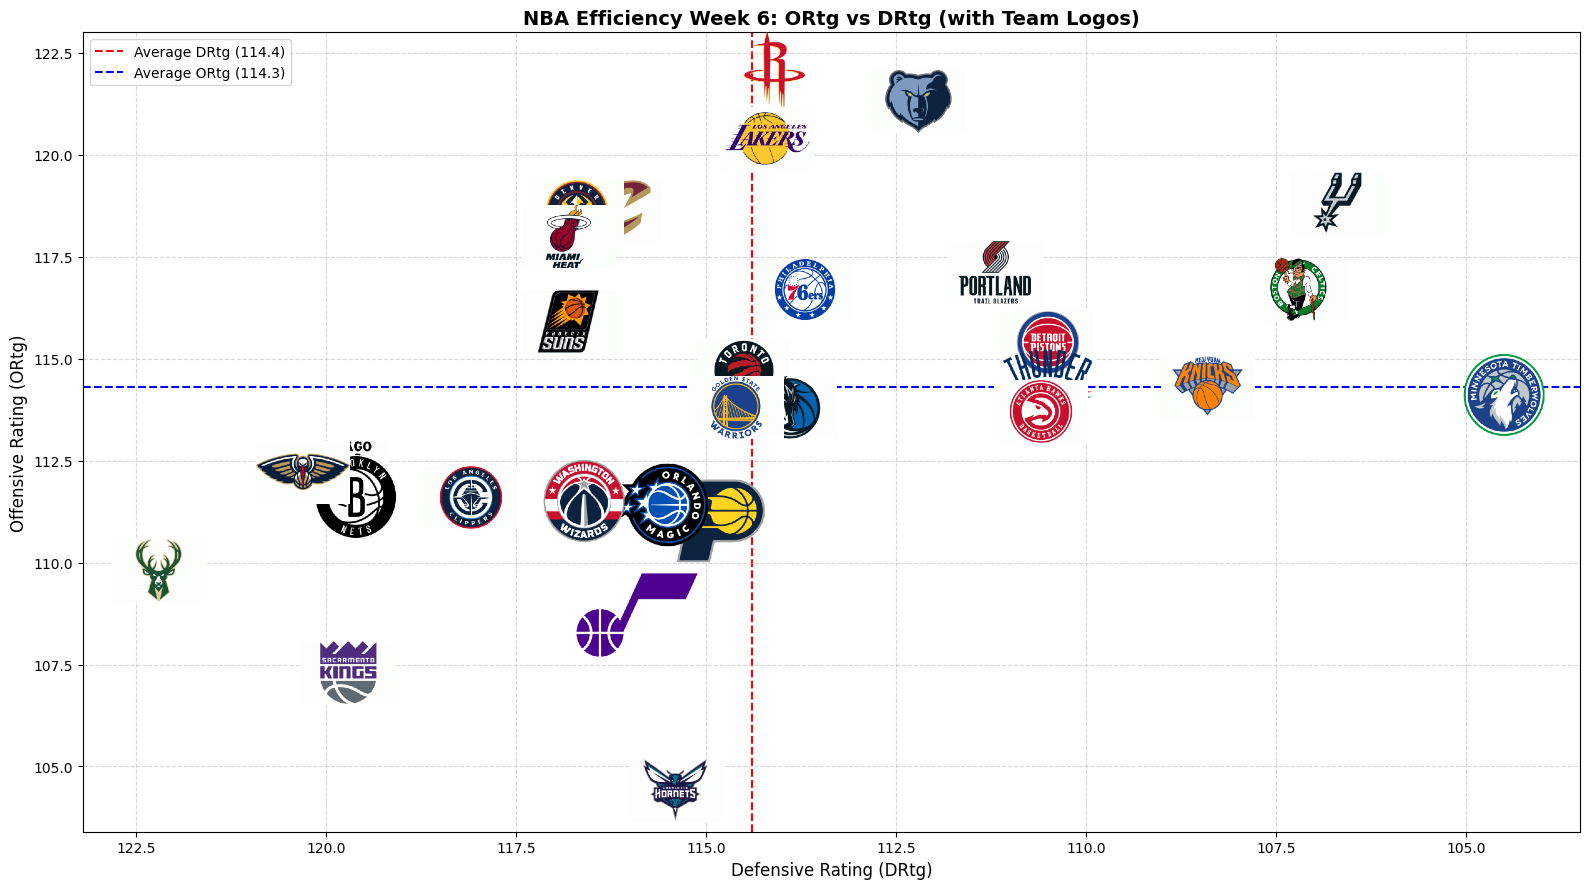

In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import pandas as pd

# Prepare the plot
fig, ax = plt.subplots(figsize=(16, 9))

# Draw reference lines
ax.axvline(x=114.4, color='red', linestyle='--', linewidth=1.5, label='Average DRtg (114.4)', zorder=1)
ax.axhline(y=114.3, color='blue', linestyle='--', linewidth=1.5, label='Average ORtg (114.3)', zorder=1)

# Define the logos folder and find all files
logo_dir = 'nba_logos'
logo_files = {}
if os.path.exists(logo_dir):
    for f in os.listdir(logo_dir):
        name, ext = os.path.splitext(f)
        logo_files[name] = os.path.join(logo_dir, f)

# Plot each point as an image
for i, row in data.iterrows():
    team = row['Team']
    x, y = row['DRtg'], row['ORtg']

    # Try to find the downloaded logo
    img_path = logo_files.get(team)
    if img_path and os.path.exists(img_path):
        try:
            img = plt.imread(img_path)
            # Create an OffsetImage
            imagebox = OffsetImage(img, zoom=0.45)  # Adjust zoom to scale logos appropriately
            ab = AnnotationBbox(imagebox, (x, y), frameon=False, pad=0.0)
            ax.add_artist(ab)
        except Exception:
            # Fallback to standard dot if image fails to read
            ax.scatter(x, y, s=150, color='gray', alpha=0.7)
    else:
        # Fallback to standard dot
        ax.scatter(x, y, s=150, color='gray', alpha=0.7)

# Configure title, labels and grid
ax.set_title('NBA Efficiency Week 6: ORtg vs DRtg (with Team Logos)', fontsize=14, fontweight='bold')
ax.set_xlabel('Defensive Rating (DRtg)', fontsize=12)
ax.set_ylabel('Offensive Rating (ORtg)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5, zorder=0)

# Set limits similar to the previous best configuration
drtg_min, drtg_max = data['DRtg'].min(), data['DRtg'].max()
ortg_min, ortg_max = data['ORtg'].min(), data['ORtg'].max()

# Lower DRtg is better (right side), higher ORtg is better (top)
ax.set_xlim(drtg_max + 1, drtg_min - 1)
ax.set_ylim(ortg_min - 1, ortg_max + 1)

ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import glob
import os
from PIL import Image


def remove_white_bg(img_path: str, out_path: str, threshold: int = 242) -> None:
  img = Image.open(img_path).convert("RGBA")
  pixels = img.getdata()

  new_pixels = []
  for r, g, b, a in pixels:
    # Turn near-white pixels transparent; keep existing alpha if already transparent
    if a > 0 and r >= threshold and g >= threshold and b >= threshold:
      new_pixels.append((r, g, b, 0))
    else:
      new_pixels.append((r, g, b, a))

  img.putdata(new_pixels)
  # Crop excess empty transparent padding so logos size consistently
  bbox = img.getbbox()
  if bbox:
    img = img.crop(bbox)
  img.save(out_path, "PNG")


os.makedirs("nba_logos_clean", exist_ok=True)
for path in glob.glob("nba_logos/*"):
  name = os.path.splitext(os.path.basename(path))[0]
  remove_white_bg(path, os.path.join("nba_logos_clean", f"{name}.png"))

In [ ]:
import glob
import os
from PIL import Image


def make_uniform_logo(
    img_path: str, out_path: str, canvas_size: int = 80, padding: int = 6
) -> None:
  img = Image.open(img_path).convert("RGBA")

  # Trim transparent margins first so wide/tall whitespace doesn't skew scale
  bbox = img.getbbox()
  if bbox:
    img = img.crop(bbox)

  max_inner = canvas_size - (2 * padding)
  w, h = img.size

  # Scale proportionally so largest side fits max_inner
  scale = min(max_inner / w, max_inner / h)
  new_w = max(1, int(round(w * scale)))
  new_h = max(1, int(round(h * scale)))
  resized = img.resize((new_w, new_h), Image.Resampling.LANCZOS)

  # Center on a uniform transparent square canvas
  canvas = Image.new("RGBA", (canvas_size, canvas_size), (0, 0, 0, 0))
  offset_x = (canvas_size - new_w) // 2
  offset_y = (canvas_size - new_h) // 2
  canvas.paste(resized, (offset_x, offset_y), resized)

  canvas.save(out_path, "PNG")


os.makedirs("nba_logos_uniform", exist_ok=True)
for path in glob.glob("nba_logos_clean/*.png"):
  name = os.path.splitext(os.path.basename(path))[0]
  make_uniform_logo(
      path,
      os.path.join("nba_logos_uniform", f"{name}.png"),
      canvas_size=80,
      padding=6,
  )

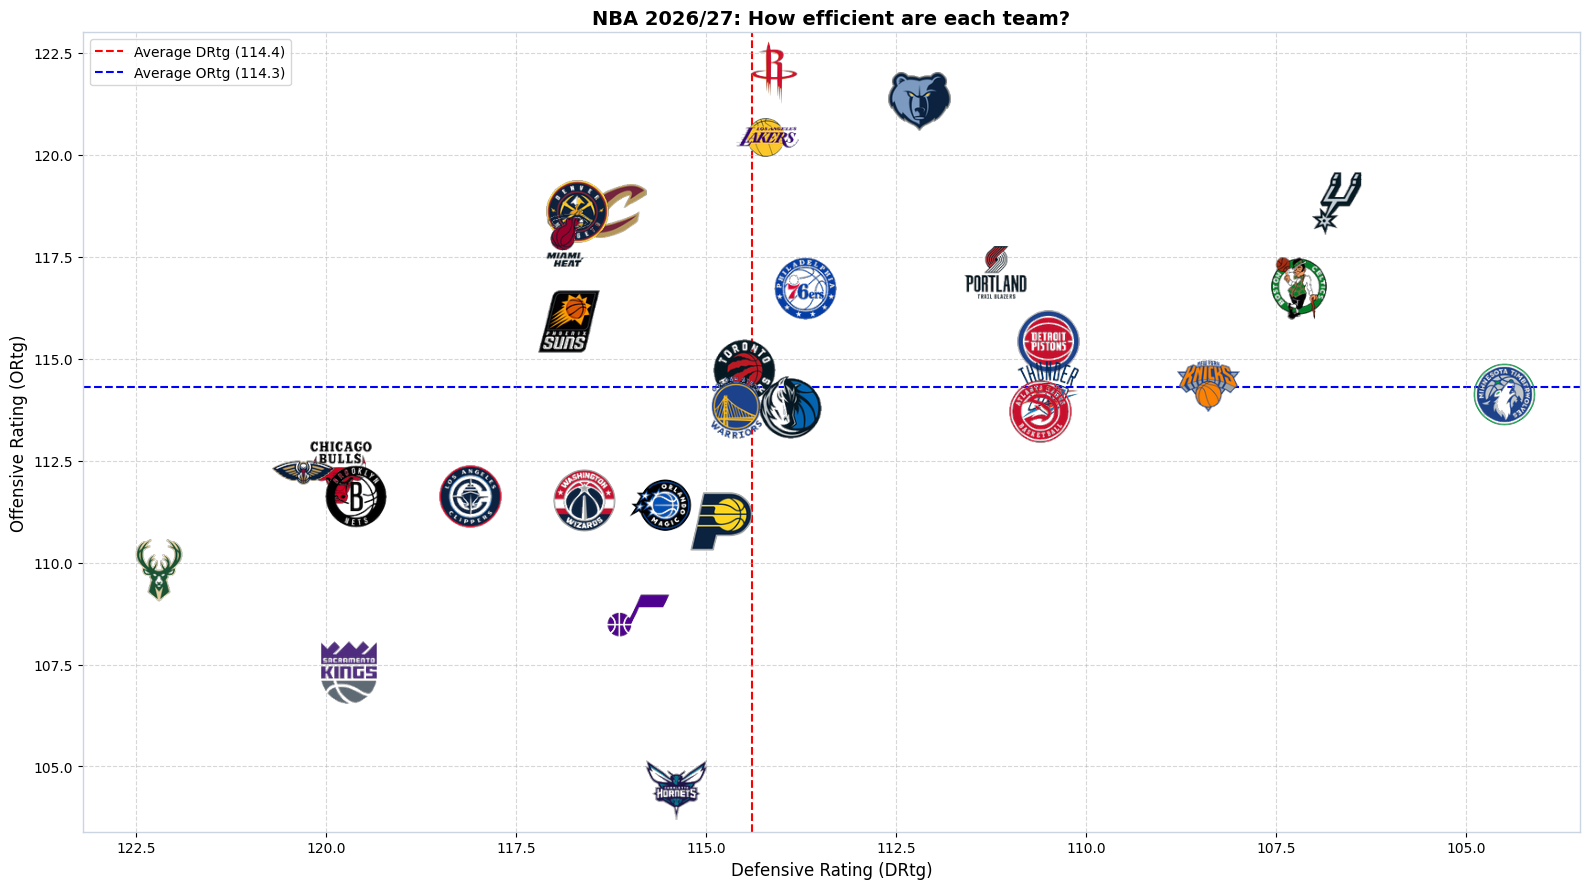

In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import pandas as pd

# Prepare the plot
fig, ax = plt.subplots(figsize=(16, 9))

# Draw reference lines
ax.axvline(x=114.4, color='red', linestyle='--', linewidth=1.5, label='Average DRtg (114.4)', zorder=1)
ax.axhline(y=114.3, color='blue', linestyle='--', linewidth=1.5, label='Average ORtg (114.3)', zorder=1)

# Define the logos folder and find all files
logo_dir = 'nba_logos_uniform'
logo_files = {}
if os.path.exists(logo_dir):
    for f in os.listdir(logo_dir):
        name, ext = os.path.splitext(f)
        logo_files[name] = os.path.join(logo_dir, f)

# Plot each point as an image
for i, row in data.iterrows():
    team = row['Team']
    x, y = row['DRtg'], row['ORtg']

    # Try to find the downloaded logo
    img_path = logo_files.get(team)
    if img_path and os.path.exists(img_path):
        try:
            img = plt.imread(img_path)
            # Create an OffsetImage
            imagebox = OffsetImage(img, zoom=0.65)  # Adjust zoom to scale logos appropriately
            ab = AnnotationBbox(imagebox, (x, y), frameon=False, pad=0.0)
            ax.add_artist(ab)
        except Exception:
            # Fallback to standard dot if image fails to read
            ax.scatter(x, y, s=150, color='gray', alpha=0.7)
    else:
        # Fallback to standard dot
        ax.scatter(x, y, s=150, color='gray', alpha=0.7)

# Configure title, labels and grid
ax.set_title('NBA 2026/27: How efficient are each team?', fontsize=14, fontweight='bold')
ax.set_xlabel('Defensive Rating (DRtg)', fontsize=12)
ax.set_ylabel('Offensive Rating (ORtg)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5, zorder=0)

# Set limits similar to the previous best configuration
drtg_min, drtg_max = data['DRtg'].min(), data['DRtg'].max()
ortg_min, ortg_max = data['ORtg'].min(), data['ORtg'].max()

# Lower DRtg is better (right side), higher ORtg is better (top)
ax.set_xlim(drtg_max + 1, drtg_min - 1)
ax.set_ylim(ortg_min - 1, ortg_max + 1)

ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# --- Diagonal Net Rating = 0 Break-Even Line & Shaded Sections ---
# Get current axis bounds (remember x_left > x_right because x-axis is inverted)
x_left, x_right = ax.get_xlim()
y_bottom, y_top = ax.get_ylim()

# Create range spanning the full visible x-axis
x_vals = np.linspace(x_right, x_left, 300)

# 1. Plot the diagonal line where ORtg == DRtg (Net Rating = 0)
ax.plot(
    x_vals,
    x_vals,
    color="#0F172A",
    linestyle="-.",
    linewidth=1.5,
    alpha=0.75,
    label="Break-Even Line (NRtg = 0.0)",
    zorder=1,
)

# 2. Subtle background shading for Positive vs. Negative Net Rating
# Above line (y > x) = Positive Net Rating
ax.fill_between(
    x_vals,
    x_vals,
    y_top,
    color="#1D428A",   # NBA Blue tint
    alpha=0.05,
    zorder=0,
)

# Below line (y < x) = Negative Net Rating
ax.fill_between(
    x_vals,
    y_bottom,
    x_vals,
    color="#C8102E",   # NBA Red tint
    alpha=0.05,
    zorder=0,
)

# 3. Optional rotated label along the diagonal line
ax.text(
    108.2, 108.5,
    "BREAK-EVEN (NET RATING = 0.0)",
    rotation=33,          # Adjust angle slightly if figure aspect ratio changes
    fontfamily=FONT_NAME,
    fontweight="bold",
    fontsize=11,
    color="#0F172A",
    alpha=0.75,
    ha="center",
    va="bottom",
    zorder=2,
)

Text(108.2, 108.5, 'BREAK-EVEN (NET RATING = 0.0)')

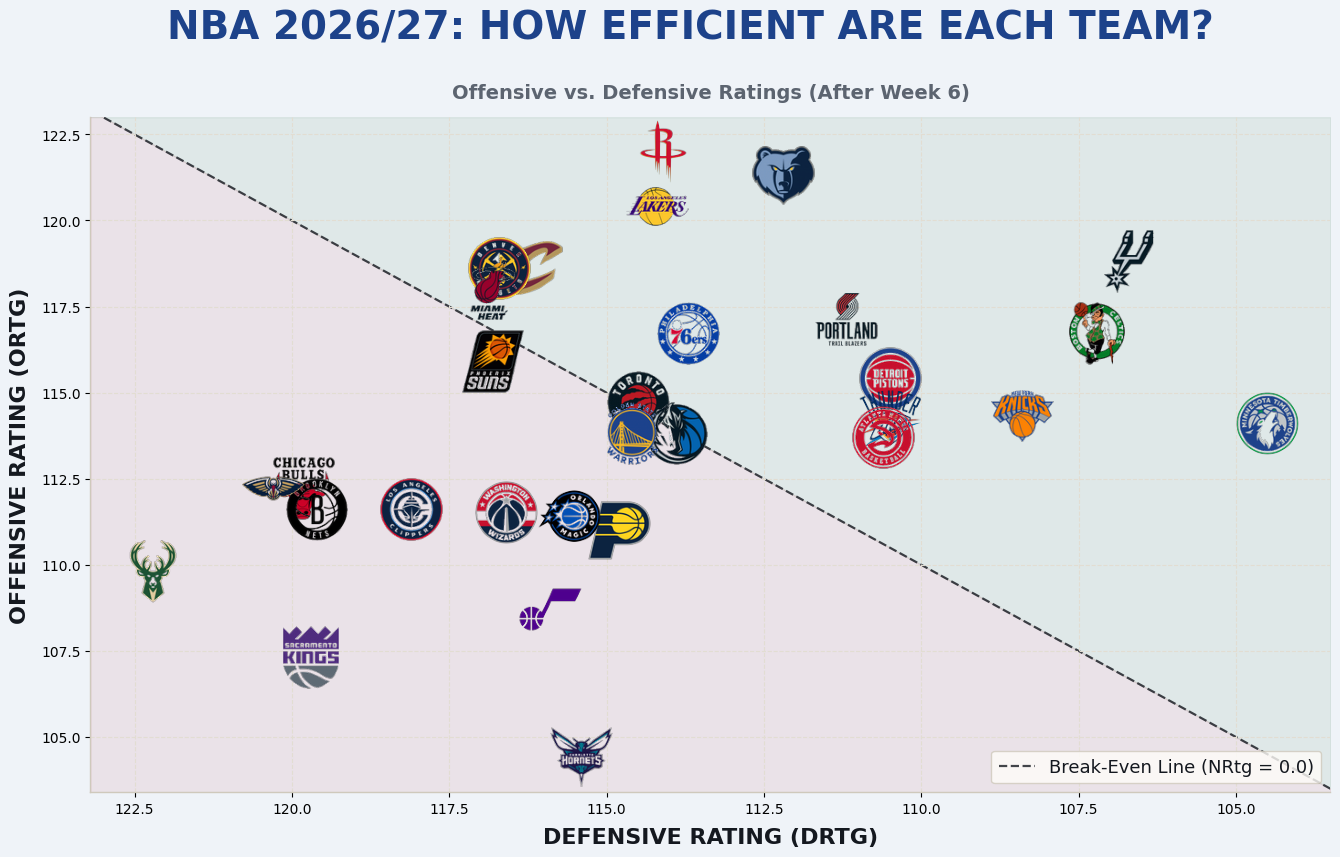

In [45]:
import os
from matplotlib import font_manager
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FONT_NAME = "Bebas Neue"
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
if os.path.exists("BebasNeue-Regular.ttf"):
  font_manager.fontManager.addfont("BebasNeue-Regular.ttf")
  FONT_NAME = font_manager.FontProperties(fname="BebasNeue-Regular.ttf").get_name()
elif FONT_NAME not in available_fonts:
  FONT_NAME = "DejaVu Sans"

BG_COLOR = "#EFF3F8"
CARD_BG = "#FFFDF9"
TEXT_DARK = "#14181F"
NBA_BLUE = "#1D428A"
MUTED_SLATE = "#5C6470"
GRID_COLOR = "#E2DDD2"
SPINE_COLOR = "#CFC9BC"
POS_COLOR = "#3F7A4C"
NEG_COLOR = "#B83A4B"

fig, ax = plt.subplots(figsize=(16, 9), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

drtg_min, drtg_max = data["DRtg"].min(), data["DRtg"].max()
ortg_min, ortg_max = data["ORtg"].min(), data["ORtg"].max()
ax.set_xlim(drtg_max + 1, drtg_min - 1)
ax.set_ylim(ortg_min - 1, ortg_max + 1)

x_left, x_right = ax.get_xlim()
y_bottom, y_top = ax.get_ylim()
x_vals = np.linspace(x_right, x_left, 300)

ax.plot(x_vals, x_vals, color=TEXT_DARK, linestyle="--", linewidth=1.6, alpha=0.8, label="Break-Even Line (NRtg = 0.0)", zorder=1)
ax.fill_between(x_vals, x_vals, y_top, color=POS_COLOR, alpha=0.09, zorder=0)
ax.fill_between(x_vals, y_bottom, x_vals, color=NEG_COLOR, alpha=0.09, zorder=0)

logo_dir = "nba_logos_uniform"
logo_files = {
    os.path.splitext(f)[0]: os.path.join(logo_dir, f)
    for f in os.listdir(logo_dir)
} if os.path.exists(logo_dir) else {}

for _, row in data.iterrows():
  team, x, y = row["Team"], row["DRtg"], row["ORtg"]
  img_path = logo_files.get(team)
  if img_path and os.path.exists(img_path):
    try:
      ab = AnnotationBbox(OffsetImage(plt.imread(img_path), zoom=0.65), (x, y), frameon=False, pad=0.0, zorder=3)
      ax.add_artist(ab)
      continue
    except Exception:
      pass
  ax.scatter(x, y, s=150, color=MUTED_SLATE, alpha=0.75, zorder=3)

fig.suptitle("NBA 2026/27: HOW EFFICIENT ARE EACH TEAM?", fontfamily=FONT_NAME, fontsize=28, color=NBA_BLUE, fontweight="bold", y=0.98)
ax.set_title("Offensive vs. Defensive Ratings (After Week 6)", fontfamily=FONT_NAME, fontsize=14, color=MUTED_SLATE, fontweight="bold", pad=14)
ax.set_xlabel("DEFENSIVE RATING (DRTG)", fontfamily=FONT_NAME, fontsize=16, fontweight="bold", color=TEXT_DARK, labelpad=8)
ax.set_ylabel("OFFENSIVE RATING (ORTG)", fontfamily=FONT_NAME, fontsize=16, fontweight="bold", color=TEXT_DARK, labelpad=8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(SPINE_COLOR)
ax.spines["bottom"].set_color(SPINE_COLOR)
ax.grid(True, linestyle="--", linewidth=0.8, color=GRID_COLOR, zorder=0)

legend = ax.legend(loc="lower right", frameon=True, facecolor=CARD_BG, edgecolor=SPINE_COLOR, fontsize=13)
for text in legend.get_texts():
  text.set_fontfamily(FONT_NAME)
  text.set_color(TEXT_DARK)

plt.subplots_adjust(top=0.86)
plt.savefig("nba_net_rating_diagonal.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

/tmp/ipykernel_2788/2484256684.py:187: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  legend = ax.legend(


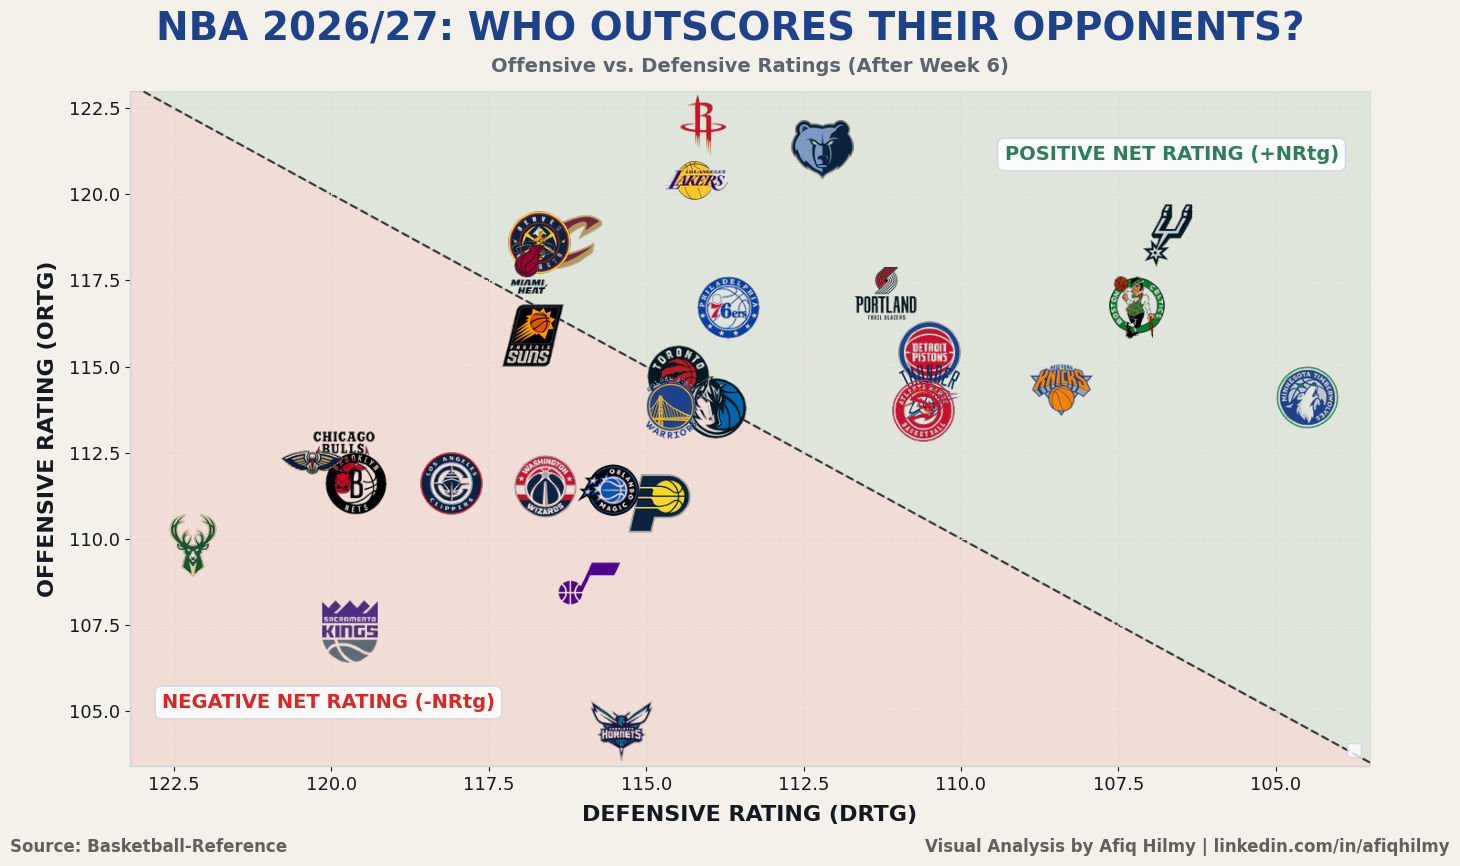

In [61]:
import os
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
import numpy as np
import pandas as pd

# --- 1. Bebas Neue Font Setup (with safe fallback) ---
FONT_NAME = "Open Sans"
available_fonts = {f.name for f in font_manager.fontManager.ttflist}

local_font_path = "BebasNeue-Regular.ttf"
if os.path.exists(local_font_path):
  font_manager.fontManager.addfont(local_font_path)
  FONT_NAME = font_manager.FontProperties(fname=local_font_path).get_name()
elif FONT_NAME not in available_fonts:
  FONT_NAME = "DejaVu Sans"

plt.rcParams["font.family"] = FONT_NAME
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 1.0

# --- 2. Custom Theme Palette ---
BG_COLOR = "#F4F1EA"
CARD_BG = "#FFFDF9"
TEXT_DARK = "#14181F"
NBA_BLUE = "#1D428A"
MUTED_SLATE = "#5C6470"
GRID_COLOR = "#E2DDD2"
SPINE_COLOR = "#CFC9BC"
POS_COLOR = "#3F7A4C"
NEG_COLOR = "#B83A4B"

# --- 3. Prepare the plot ---
fig, ax = plt.subplots(figsize=(16, 9), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

# Set limits first so diagonal line and shading cover the exact plot area
drtg_min, drtg_max = data["DRtg"].min(), data["DRtg"].max()
ortg_min, ortg_max = data["ORtg"].min(), data["ORtg"].max()

# Lower DRtg is better (right side), higher ORtg is better (top)
ax.set_xlim(drtg_max + 1, drtg_min - 1)
ax.set_ylim(ortg_min - 1, ortg_max + 1)

x_left, x_right = ax.get_xlim()  # x_left is larger (worse D), x_right is smaller (better D)
y_bottom, y_top = ax.get_ylim()
x_vals = np.linspace(x_right, x_left, 300)

# Diagonal break-even line where ORtg == DRtg (Net Rating = 0.0)
ax.plot(
    x_vals,
    x_vals,
    color=TEXT_DARK,
    linestyle="--",
    linewidth=1.6,
    alpha=0.8,
    zorder=1,
)

# Green background for Positive Net Rating (ORtg > DRtg, above/right of diagonal)
ax.fill_between(
    x_vals,
    x_vals,
    y_top,
    color=POS_GREEN,
    alpha=0.10,
    zorder=0,
)

# Red background for Negative Net Rating (ORtg < DRtg, below/left of diagonal)
ax.fill_between(
    x_vals,
    y_bottom,
    x_vals,
    color=NEG_RED,
    alpha=0.10,
    zorder=0,
)

ax.text(
    x_right + (x_left - x_right) * 0.16,
    y_top - (y_top - y_bottom) * 0.08,
    "POSITIVE NET RATING (+NRtg)",
    fontfamily=FONT_NAME,
    fontweight="bold",
    fontsize=14,
    color=POS_GREEN,
    ha="center",
    va="top",
    bbox=label_box,
    zorder=2,
)

ax.text(
    x_left - (x_left - x_right) * 0.16,
    y_bottom + (y_top - y_bottom) * 0.08,
    "NEGATIVE NET RATING (-NRtg)",
    fontfamily=FONT_NAME,
    fontweight="bold",
    fontsize=14,
    color=NEG_RED,
    ha="center",
    va="bottom",
    bbox=label_box,
    zorder=2,
)

# Define the logos folder and find all files
logo_dir = "nba_logos_uniform"
logo_files = {}
if os.path.exists(logo_dir):
  for f in os.listdir(logo_dir):
    name, ext = os.path.splitext(f)
    logo_files[name] = os.path.join(logo_dir, f)

# Plot each point as an image
for i, row in data.iterrows():
  team = row["Team"]
  x, y = row["DRtg"], row["ORtg"]

  # Try to find the downloaded logo
  img_path = logo_files.get(team)
  if img_path and os.path.exists(img_path):
    try:
      img = plt.imread(img_path)
      # Create an OffsetImage
      imagebox = OffsetImage(
          img, zoom=0.65
      )  # Adjust zoom to scale logos appropriately
      ab = AnnotationBbox(imagebox, (x, y), frameon=False, pad=0.0, zorder=3)
      ax.add_artist(ab)
    except Exception:
      # Fallback to standard dot if image fails to read
      ax.scatter(x, y, s=150, color=MUTED_SLATE, alpha=0.7, zorder=3)
  else:
    # Fallback to standard dot
    ax.scatter(x, y, s=150, color=MUTED_SLATE, alpha=0.7, zorder=3)

# Configure Titles (Main Title + Subtitle)
fig.suptitle(
    "NBA 2026/27: WHO OUTSCORES THEIR OPPONENTS?",
    fontfamily=FONT_NAME,
    fontsize=28,
    color=NBA_BLUE,
    fontweight="bold",
    y=0.95,
)

ax.set_title(
    "Offensive vs. Defensive Ratings (After Week 6)",
    fontfamily=FONT_NAME,
    fontsize=14,
    color=MUTED_SLATE,
    fontweight="bold",
    pad=14,
)

ax.set_xlabel(
    "DEFENSIVE RATING (DRTG)",
    fontfamily=FONT_NAME,
    fontsize=16,
    fontweight="bold",
    color=TEXT_DARK,
    labelpad=8,
)
ax.set_ylabel(
    "OFFENSIVE RATING (ORTG)",
    fontfamily=FONT_NAME,
    fontsize=16,
    fontweight="bold",
    color=TEXT_DARK,
    labelpad=8,
)

ax.tick_params(axis="both", colors=TEXT_DARK, labelsize=13)
for label in ax.get_xticklabels() + ax.get_yticklabels():
  label.set_fontfamily(FONT_NAME)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CBD5E1")
ax.spines["bottom"].set_color("#CBD5E1")

ax.grid(True, linestyle="--", linewidth=0.8, color=GRID_COLOR, zorder=0)

legend = ax.legend(
    loc="lower right",
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CBD5E1",
    fontsize=13,
)
for text in legend.get_texts():
  text.set_fontfamily(FONT_NAME)
  text.set_color(TEXT_DARK)

# --- 8. PROFESSIONAL PORTFOLIO WATERMARK ---
plt.text(
    0.95,
    0.01,
    "Visual Analysis by Afiq Hilmy | linkedin.com/in/afiqhilmy",
    transform=plt.gcf().transFigure,
    fontsize=12,
    fontfamily=FONT_NAME,
    fontweight="bold",
    color="black",
    ha="right",
    va="bottom",
    alpha=0.6,
)

plt.text(
    0.05,
    0.01,
    "Source: Basketball-Reference",
    transform=plt.gcf().transFigure,
    fontsize=12,
    fontfamily=FONT_NAME,
    fontweight="bold",
    color="black",
    ha="left",
    va="bottom",
    alpha=0.6,
)

plt.subplots_adjust(top=0.86)
plt.show()

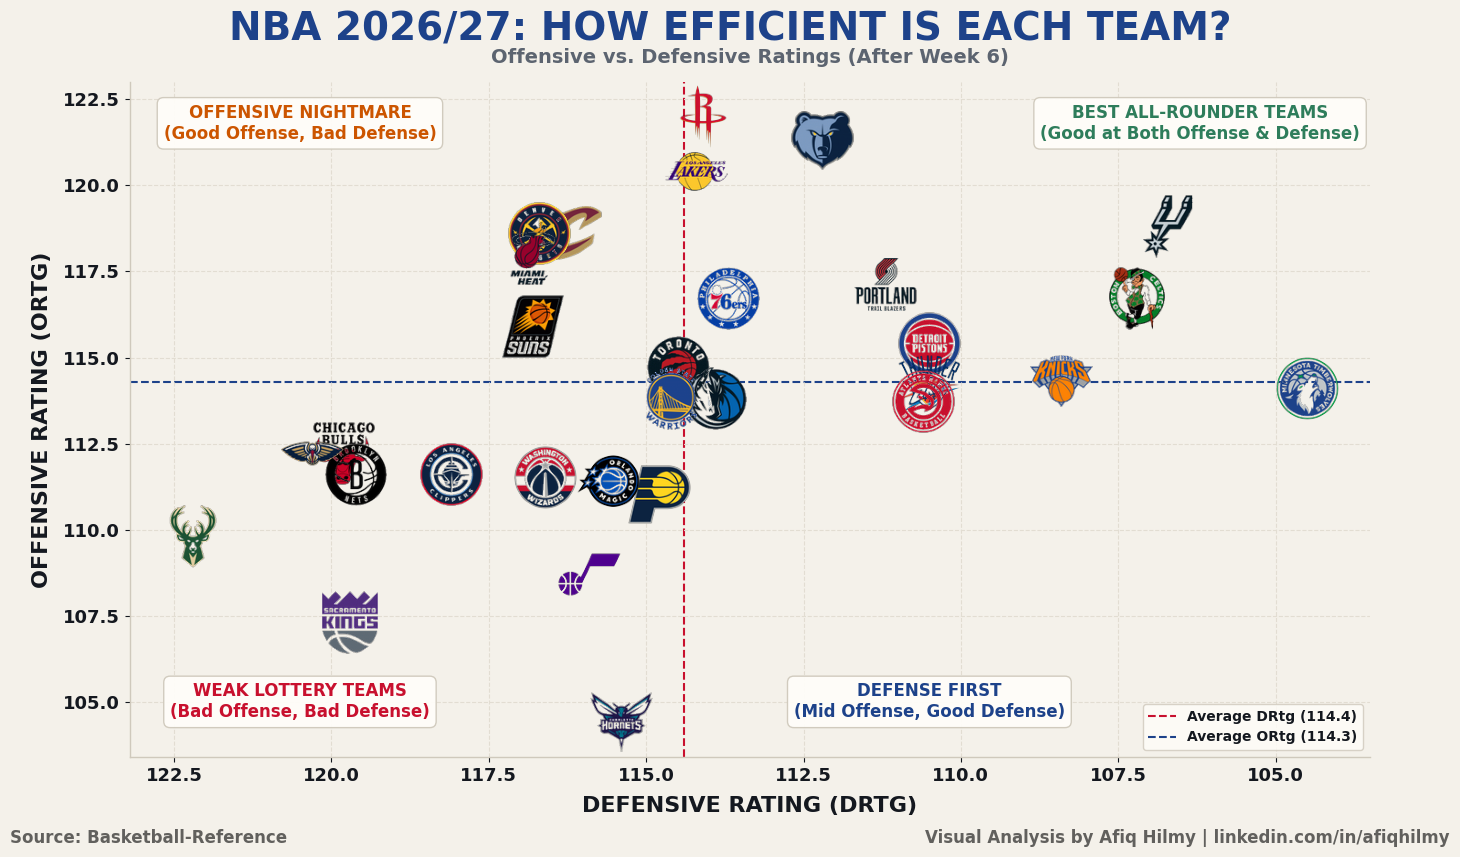

In [63]:
import os
from matplotlib import font_manager
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. Bebas Neue Font Setup (with safe fallback) ---
FONT_NAME = "Bebas Neue"
available_fonts = {f.name for f in font_manager.fontManager.ttflist}

local_font_path = "BebasNeue-Regular.ttf"
if os.path.exists(local_font_path):
  font_manager.fontManager.addfont(local_font_path)
  FONT_NAME = font_manager.FontProperties(fname=local_font_path).get_name()
elif FONT_NAME not in available_fonts:
  FONT_NAME = "DejaVu Sans"

plt.rcParams["font.family"] = FONT_NAME
plt.rcParams["axes.edgecolor"] = "#CFC9BC"
plt.rcParams["axes.linewidth"] = 1.0

# --- 2. Editorial Light Palette ---
BG_COLOR = "#F4F1EA"
CARD_BG = "#FFFDF9"
TEXT_DARK = "#14181F"
NBA_BLUE = "#1D428A"
NBA_RED = "#C8102E"
MUTED_SLATE = "#5C6470"
GRID_COLOR = "#E2DDD2"
SPINE_COLOR = "#CFC9BC"
POS_GREEN = "#2E7D5B"

# --- 3. Prepare the plot ---
fig, ax = plt.subplots(figsize=(16, 9), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

avg_drtg = 114.4
avg_ortg = 114.3

# Draw average reference lines
ax.axvline(
    x=avg_drtg,
    color=NBA_RED,
    linestyle="--",
    linewidth=1.5,
    label=f"Average DRtg ({avg_drtg:.1f})",
    zorder=1,
)
ax.axhline(
    y=avg_ortg,
    color=NBA_BLUE,
    linestyle="--",
    linewidth=1.5,
    label=f"Average ORtg ({avg_ortg:.1f})",
    zorder=1,
)

# Define the logos folder and find all files
logo_dir = "nba_logos_uniform"
logo_files = {}
if os.path.exists(logo_dir):
  for f in os.listdir(logo_dir):
    name, ext = os.path.splitext(f)
    logo_files[name] = os.path.join(logo_dir, f)

# Plot each point as an image
for _, row in data.iterrows():
  team = row["Team"]
  x, y = row["DRtg"], row["ORtg"]

  img_path = logo_files.get(team)
  if img_path and os.path.exists(img_path):
    try:
      img = plt.imread(img_path)
      imagebox = OffsetImage(img, zoom=0.65)
      ab = AnnotationBbox(imagebox, (x, y), frameon=False, pad=0.0, zorder=3)
      ax.add_artist(ab)
    except Exception:
      ax.scatter(x, y, s=150, color=MUTED_SLATE, alpha=0.75, zorder=3)
  else:
    ax.scatter(x, y, s=150, color=MUTED_SLATE, alpha=0.75, zorder=3)

# --- 4. Titles, labels, ticks, spines, and limits ---
fig.suptitle(
    "NBA 2026/27: HOW EFFICIENT IS EACH TEAM?",
    fontfamily=FONT_NAME,
    fontsize=28,
    color=NBA_BLUE,
    fontweight="bold",
    y=0.94,
)

ax.set_title(
    "Offensive vs. Defensive Ratings (After Week 6)",
    fontfamily=FONT_NAME,
    fontsize=14,
    color=MUTED_SLATE,
    fontweight="bold",
    pad=14,
)

ax.set_xlabel(
    "DEFENSIVE RATING (DRTG)",
    fontfamily=FONT_NAME,
    fontsize=16,
    fontweight="bold",
    color=TEXT_DARK,
    labelpad=8,
)
ax.set_ylabel(
    "OFFENSIVE RATING (ORTG)",
    fontfamily=FONT_NAME,
    fontsize=16,
    fontweight="bold",
    color=TEXT_DARK,
    labelpad=8,
)

ax.tick_params(axis="both", colors=TEXT_DARK, labelsize=13)
for label in ax.get_xticklabels() + ax.get_yticklabels():
  label.set_fontfamily(FONT_NAME)
  label.set_fontweight("bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(SPINE_COLOR)
ax.spines["bottom"].set_color(SPINE_COLOR)

ax.grid(True, linestyle="--", linewidth=0.8, color=GRID_COLOR, zorder=0)

drtg_min, drtg_max = data["DRtg"].min(), data["DRtg"].max()
ortg_min, ortg_max = data["ORtg"].min(), data["ORtg"].max()

# Lower DRtg is better (right side), higher ORtg is better (top)
ax.set_xlim(drtg_max + 1, drtg_min - 1)
ax.set_ylim(ortg_min - 1, ortg_max + 1)

# --- 5. Four Quadrant Labels ---
quadrant_style = dict(
    fontfamily=FONT_NAME,
    fontweight="bold",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.38",
        facecolor=CARD_BG,
        edgecolor=SPINE_COLOR,
        linewidth=1.0,
        alpha=0.95,
    ),
    zorder=2,
)

# 1. Top-Left: High ORtg, High DRtg
ax.text(
    120.5,
    121.8,
    "OFFENSIVE NIGHTMARE\n(Good Offense, Bad Defense)",
    fontsize=12,
    color="#CC5500",
    **quadrant_style,
)

# 2. Top-Right: High ORtg, Low DRtg
ax.text(
    106.2,
    121.8,
    "BEST ALL-ROUNDER TEAMS\n(Good at Both Offense & Defense)",
    fontsize=12,
    color=POS_GREEN,
    **quadrant_style,
)

# 3. Bottom-Left: Low ORtg, High DRtg
ax.text(
    120.5,
    105.0,
    "WEAK LOTTERY TEAMS\n(Bad Offense, Bad Defense)",
    fontsize=12,
    color=NBA_RED,
    **quadrant_style,
)

# 4. Bottom-Right: Low ORtg, Low DRtg
ax.text(
    110.5,
    105.0,
    "DEFENSE FIRST\n(Mid Offense, Good Defense)",
    fontsize=12,
    color=NBA_BLUE,
    **quadrant_style,
)

legend = ax.legend(
    loc="lower right",
    frameon=True,
    facecolor=CARD_BG,
    edgecolor=SPINE_COLOR,
    fontsize=10,
)
for text in legend.get_texts():
  text.set_fontfamily(FONT_NAME)
  text.set_fontweight("bold")
  text.set_color(TEXT_DARK)

# --- 6. Professional Portfolio Watermark ---
plt.text(
    0.95,
    0.01,
    "Visual Analysis by Afiq Hilmy | linkedin.com/in/afiqhilmy",
    transform=plt.gcf().transFigure,
    fontsize=12,
    fontfamily=FONT_NAME,
    fontweight="bold",
    color="black",
    ha="right",
    va="bottom",
    alpha=0.6,
)

plt.text(
    0.05,
    0.01,
    "Source: Basketball-Reference",
    transform=plt.gcf().transFigure,
    fontsize=12,
    fontfamily=FONT_NAME,
    fontweight="bold",
    color="black",
    ha="left",
    va="bottom",
    alpha=0.6,
)



plt.subplots_adjust(top=0.86)
plt.savefig("nba_efficiency_quadrants.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()